<a href="https://colab.research.google.com/github/LeylahfrA01178568/2039_data_visualization/blob/main/attempt__slicing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Leylah Fragoso Carvajal**

This activity is to understand what was done on the notes 041, from tec03

In [2]:
import pandas as pd
import numpy as np

In [6]:
path = 'https://raw.githubusercontent.com/tec03/Datasets/refs/heads/main/datasets/multi_index.csv'

In [7]:
df = pd.read_csv(path)

In [8]:
df.head() #visualize original dataset

,Unnamed: 0,Unnamed: 1,Night,Night.1,Night.2,Day,Day.1,Day.2
0,NaN,NaN,Weather,Wind,Max Temperature,Weather,Wind,Max Temperature
1,City,Date,NaN,NaN,NaN,NaN,NaN,NaN
2,London,01/07/19,Shower,SW 16 mph,18,Shower,SW 16 mph,28
3,London,02/07/19,Heavy rain,SW 16 mph,17,Shower,SW 16 mph,29
4,London,03/07/19,Heavy rain,SW 16 mph,19,Scattered showers,SW 16 mph,29


## 0. Understanding pivot table

The following cell code reads the original data set and presents it as city and date as index columns, and the header will divide into 2 categories the variables, day and night.

In [9]:
df = pd.read_csv(path,
    index_col=[0,1],
    header=[0,1]
)
df.head(2)

Night                                Day             \
                    Weather       Wind Max Temperature Weather       Wind   
City   Date                                                                 
London 01/07/19      Shower  SW 16 mph              18  Shower  SW 16 mph   
       02/07/19  Heavy rain  SW 16 mph              17  Shower  SW 16 mph   

                                 
                Max Temperature  
City   Date                      
London 01/07/19              28  
       02/07/19              29

In [11]:
# arrange so day goes first, given its alphabetical order
df_sorted = df.sort_index(axis=1)
df

Night                             \
                              Weather       Wind Max Temperature   
City      Date                                                     
London    01/07/19             Shower  SW 16 mph              18   
          02/07/19         Heavy rain  SW 16 mph              17   
          03/07/19         Heavy rain  SW 16 mph              19   
          04/07/19      Mostly cloudy  SW 16 mph              23   
Oxford    01/07/19             Shower  SW 16 mph              19   
          02/07/19             Shower  SW 16 mph              19   
          03/07/19  Scattered showers  SW 16 mph              22   
          04/07/19             Shower  SW 16 mph              21   
Cambridge 01/07/19             Shower  SW 16 mph              17   
          02/07/19  Scattered showers   E 20 mph              16   
          03/07/19  Scattered showers  SE 10 mph              16   
          04/07/19      Mostly cloudy   S 25 mph              16   

                                  Day                             
                              Weather       Wind Max Temperature  
City      Date                                                    
London    01/07/19             Shower  SW 16 mph              28  
          02/07/19             Shower  SW 16 mph              29  
          03/07/19  Scattered showers  SW 16 mph              29  
          04/07/19      Mostly cloudy  SW 16 mph              31  
Oxford    01/07/19             Shower  SW 13 mph              25  
          02/07/19             Shower  SW 16 mph              26  
          03/07/19  Scattered showers  SW 16 mph              28  
          04/07/19             Shower  SW 14 mph              25  
Cambridge 01/07/19             Shower  SW 16 mph              24  
          02/07/19  Scattered showers   E 20 mph              21  
          03/07/19  Scattered showers  SE 10 mph              22  
          04/07/19             Shower   S 25 mph              22

The next code arranges rows alphabetically

In [12]:
df = df.sort_index()
df

Night                             \
                              Weather       Wind Max Temperature   
City      Date                                                     
Cambridge 01/07/19             Shower  SW 16 mph              17   
          02/07/19  Scattered showers   E 20 mph              16   
          03/07/19  Scattered showers  SE 10 mph              16   
          04/07/19      Mostly cloudy   S 25 mph              16   
London    01/07/19             Shower  SW 16 mph              18   
          02/07/19         Heavy rain  SW 16 mph              17   
          03/07/19         Heavy rain  SW 16 mph              19   
          04/07/19      Mostly cloudy  SW 16 mph              23   
Oxford    01/07/19             Shower  SW 16 mph              19   
          02/07/19             Shower  SW 16 mph              19   
          03/07/19  Scattered showers  SW 16 mph              22   
          04/07/19             Shower  SW 16 mph              21   

                                  Day                             
                              Weather       Wind Max Temperature  
City      Date                                                    
Cambridge 01/07/19             Shower  SW 16 mph              24  
          02/07/19  Scattered showers   E 20 mph              21  
          03/07/19  Scattered showers  SE 10 mph              22  
          04/07/19             Shower   S 25 mph              22  
London    01/07/19             Shower  SW 16 mph              28  
          02/07/19             Shower  SW 16 mph              29  
          03/07/19  Scattered showers  SW 16 mph              29  
          04/07/19      Mostly cloudy  SW 16 mph              31  
Oxford    01/07/19             Shower  SW 13 mph              25  
          02/07/19             Shower  SW 16 mph              26  
          03/07/19  Scattered showers  SW 16 mph              28  
          04/07/19             Shower  SW 14 mph              25

In [13]:
idx = pd.Index(list('abc'))
idx

Index(['a', 'b', 'c'], dtype='object')

In [14]:
idx.get_level_values(0)

Index(['a', 'b', 'c'], dtype='object')

### Understand index levels

In [15]:
df.columns.levels

FrozenList([['Day', 'Night'], ['Max Temperature', 'Weather', 'Wind']])

In [16]:
df.columns.levels[0] # call the first column level

Index(['Day', 'Night'], dtype='object')

In [17]:
df.columns.levels[1] # call the second column level

Index(['Max Temperature', 'Weather', 'Wind'], dtype='object')

In [18]:
df.index.levels # display the first in dex ( city)

FrozenList([['Cambridge', 'London', 'Oxford'], ['01/07/19', '02/07/19', '03/07/19', '04/07/19']])

In [19]:
df.index.levels[1] # display the second index ( date)

Index(['01/07/19', '02/07/19', '03/07/19', '04/07/19'], dtype='object', name='Date')

#### Display the values per index level

In [20]:
df.columns.get_level_values(0) # values per row of column index 1

Index(['Night', 'Night', 'Night', 'Day', 'Day', 'Day'], dtype='object')

In [21]:
df.columns.get_level_values(1) # values per row of column  index 2

Index(['Weather', 'Wind', 'Max Temperature', 'Weather', 'Wind',
       'Max Temperature'],
      dtype='object')

In [22]:
df.index.get_level_values(0) # values per column row index 1

Index(['Cambridge', 'Cambridge', 'Cambridge', 'Cambridge', 'London', 'London',
       'London', 'London', 'Oxford', 'Oxford', 'Oxford', 'Oxford'],
      dtype='object', name='City')

In [23]:
df.index.get_level_values(1) # values per column row index 2

Index(['01/07/19', '02/07/19', '03/07/19', '04/07/19', '01/07/19', '02/07/19',
       '03/07/19', '04/07/19', '01/07/19', '02/07/19', '03/07/19', '04/07/19'],
      dtype='object', name='Date')

In [24]:
df

Night                             \
                              Weather       Wind Max Temperature   
City      Date                                                     
Cambridge 01/07/19             Shower  SW 16 mph              17   
          02/07/19  Scattered showers   E 20 mph              16   
          03/07/19  Scattered showers  SE 10 mph              16   
          04/07/19      Mostly cloudy   S 25 mph              16   
London    01/07/19             Shower  SW 16 mph              18   
          02/07/19         Heavy rain  SW 16 mph              17   
          03/07/19         Heavy rain  SW 16 mph              19   
          04/07/19      Mostly cloudy  SW 16 mph              23   
Oxford    01/07/19             Shower  SW 16 mph              19   
          02/07/19             Shower  SW 16 mph              19   
          03/07/19  Scattered showers  SW 16 mph              22   
          04/07/19             Shower  SW 16 mph              21   

                                  Day                             
                              Weather       Wind Max Temperature  
City      Date                                                    
Cambridge 01/07/19             Shower  SW 16 mph              24  
          02/07/19  Scattered showers   E 20 mph              21  
          03/07/19  Scattered showers  SE 10 mph              22  
          04/07/19             Shower   S 25 mph              22  
London    01/07/19             Shower  SW 16 mph              28  
          02/07/19             Shower  SW 16 mph              29  
          03/07/19  Scattered showers  SW 16 mph              29  
          04/07/19      Mostly cloudy  SW 16 mph              31  
Oxford    01/07/19             Shower  SW 13 mph              25  
          02/07/19             Shower  SW 16 mph              26  
          03/07/19  Scattered showers  SW 16 mph              28  
          04/07/19             Shower  SW 14 mph              25

### 1. Access first level

In [25]:

df.loc[:, 'Day'] # just display de values for day index column 1

Weather       Wind  Max Temperature
City      Date                                                   
Cambridge 01/07/19             Shower  SW 16 mph               24
          02/07/19  Scattered showers   E 20 mph               21
          03/07/19  Scattered showers  SE 10 mph               22
          04/07/19             Shower   S 25 mph               22
London    01/07/19             Shower  SW 16 mph               28
          02/07/19             Shower  SW 16 mph               29
          03/07/19  Scattered showers  SW 16 mph               29
          04/07/19      Mostly cloudy  SW 16 mph               31
Oxford    01/07/19             Shower  SW 13 mph               25
          02/07/19             Shower  SW 16 mph               26
          03/07/19  Scattered showers  SW 16 mph               28
          04/07/19             Shower  SW 14 mph               25

In [26]:
df.loc['London' , 'Day'] # displays values for the city london during the day

,Weather,Wind,Max Temperature
Date,,,
01/07/19,Shower,SW 16 mph,28
02/07/19,Shower,SW 16 mph,29
03/07/19,Scattered showers,SW 16 mph,29
04/07/19,Mostly cloudy,SW 16 mph,31


In [27]:
df.loc['London' , :] # displays all the values, fro both day and night, in London

Night                                           Day  \
                Weather       Wind Max Temperature            Weather   
Date                                                                    
01/07/19         Shower  SW 16 mph              18             Shower   
02/07/19     Heavy rain  SW 16 mph              17             Shower   
03/07/19     Heavy rain  SW 16 mph              19  Scattered showers   
04/07/19  Mostly cloudy  SW 16 mph              23      Mostly cloudy   

                                     
               Wind Max Temperature  
Date                                 
01/07/19  SW 16 mph              28  
02/07/19  SW 16 mph              29  
03/07/19  SW 16 mph              29  
04/07/19  SW 16 mph              31

Next code changes the row of the date into a columns

In [28]:
df.index

MultiIndex([('Cambridge', '01/07/19'),
            ('Cambridge', '02/07/19'),
            ('Cambridge', '03/07/19'),
            ('Cambridge', '04/07/19'),
            (   'London', '01/07/19'),
            (   'London', '02/07/19'),
            (   'London', '03/07/19'),
            (   'London', '04/07/19'),
            (   'Oxford', '01/07/19'),
            (   'Oxford', '02/07/19'),
            (   'Oxford', '03/07/19'),
            (   'Oxford', '04/07/19')],
           names=['City', 'Date'])

In [29]:
df.columns

MultiIndex([('Night',         'Weather'),
            ('Night',            'Wind'),
            ('Night', 'Max Temperature'),
            (  'Day',         'Weather'),
            (  'Day',            'Wind'),
            (  'Day', 'Max Temperature')],
           )

### 2. Multilevel index

In [30]:
df.loc['London' , '01/07/19'].to_frame().transpose() # select the specific row and transform the dataframe hpziontally (date )

Night                                Day             \
                Weather       Wind Max Temperature Weather       Wind   
London 01/07/19  Shower  SW 16 mph              18  Shower  SW 16 mph   

                                 
                Max Temperature  
London 01/07/19              28

In [31]:
# Select multiple rows
df.loc[
    ('London' , ['01/07/19','02/07/19'] ) ,
    'Day'
]

Weather       Wind  Max Temperature
City   Date                                        
London 01/07/19  Shower  SW 16 mph               28
       02/07/19  Shower  SW 16 mph               29

In [32]:
# Select multiple columns
df.loc[
    'London' ,
    ('Day', ['Weather', 'Wind'])
]

Day           
                    Weather       Wind
Date                                  
01/07/19             Shower  SW 16 mph
02/07/19             Shower  SW 16 mph
03/07/19  Scattered showers  SW 16 mph
04/07/19      Mostly cloudy  SW 16 mph

### 3. Selecting a range of data via slice

In [33]:
df.loc[(['London', 'Cambridge'], '02/07/19'), 'Day']

,,Weather,Wind,Max Temperature
City,Date,,,
London,02/07/19,Shower,SW 16 mph,29
Cambridge,02/07/19,Scattered showers,E 20 mph,21


In [34]:
# Access to just day values
df.loc[
    'Cambridge':'Oxford',
    'Day'
]

Weather       Wind  Max Temperature
City      Date                                                   
Cambridge 01/07/19             Shower  SW 16 mph               24
          02/07/19  Scattered showers   E 20 mph               21
          03/07/19  Scattered showers  SE 10 mph               22
          04/07/19             Shower   S 25 mph               22
London    01/07/19             Shower  SW 16 mph               28
          02/07/19             Shower  SW 16 mph               29
          03/07/19  Scattered showers  SW 16 mph               29
          04/07/19      Mostly cloudy  SW 16 mph               31
Oxford    01/07/19             Shower  SW 13 mph               25
          02/07/19             Shower  SW 16 mph               26
          03/07/19  Scattered showers  SW 16 mph               28
          04/07/19             Shower  SW 14 mph               25

In [35]:
df.loc[
    ('London', '01/07/19'):('London','03/07/19'),
    'Day'
] # show specific values  for london and specific dates during day

Weather       Wind  Max Temperature
City   Date                                                   
London 01/07/19             Shower  SW 16 mph               28
       02/07/19             Shower  SW 16 mph               29
       03/07/19  Scattered showers  SW 16 mph               29

In [36]:
df.loc[
    ('Cambridge', '02/07/19'):('London','02/07/19'),
    'Day'
]

Weather       Wind  Max Temperature
City      Date                                                   
Cambridge 02/07/19  Scattered showers   E 20 mph               21
          03/07/19  Scattered showers  SE 10 mph               22
          04/07/19             Shower   S 25 mph               22
London    01/07/19             Shower  SW 16 mph               28
          02/07/19             Shower  SW 16 mph               29

### 4. Selecting all content using slice`(None)`

The following code is a mistake because we can't use : inside a tuple for slicing

In [37]:
df.loc[
    ( : , '02/07/19'),
    'Day'
]

SyntaxError: invalid syntax (958731592.py, line 2)

Correct syntax:

In [40]:
df.loc[
    ('London', slice(None)),
    'Day'
] # slice (None) works as select all possible dates for london in second level index

Weather       Wind  Max Temperature
City   Date                                                   
London 01/07/19             Shower  SW 16 mph               28
       02/07/19             Shower  SW 16 mph               29
       03/07/19  Scattered showers  SW 16 mph               29
       04/07/19      Mostly cloudy  SW 16 mph               31

In [41]:
df.loc[
    ('London' ), #select all london content during day
    'Day'
]

,Weather,Wind,Max Temperature
Date,,,
01/07/19,Shower,SW 16 mph,28
02/07/19,Shower,SW 16 mph,29
03/07/19,Scattered showers,SW 16 mph,29
04/07/19,Mostly cloudy,SW 16 mph,31


#### only display a particular date

In [42]:
df.loc[
    (slice(None) , '02/07/19'),
    'Day']

,,Weather,Wind,Max Temperature
City,Date,,,
Cambridge,02/07/19,Scattered showers,E 20 mph,21
London,02/07/19,Shower,SW 16 mph,29
Oxford,02/07/19,Shower,SW 16 mph,26


### 5. Using cross-section `xs()`


If you want to select all data for the date `'02/07/19'` across all cities, instead of using `df.loc[(slice(None), '02/07/19'), :]`, you can write:

In [43]:
df.xs('02/07/19',
      level='Date'
     )

Night                                           Day  \
                     Weather       Wind Max Temperature            Weather   
City                                                                         
Cambridge  Scattered showers   E 20 mph              16  Scattered showers   
London            Heavy rain  SW 16 mph              17             Shower   
Oxford                Shower  SW 16 mph              19             Shower   

                                      
                Wind Max Temperature  
City                                  
Cambridge   E 20 mph              21  
London     SW 16 mph              29  
Oxford     SW 16 mph              26

The following code shows the usage of .xs() for specific level indexing

In [44]:
df.xs(
    ('London', '02/07/19'),
      level=['City','Date']
     )

Night                                Day             \
                    Weather       Wind Max Temperature Weather       Wind   
City   Date                                                                 
London 02/07/19  Heavy rain  SW 16 mph              17  Shower  SW 16 mph   

                                 
                Max Temperature  
City   Date                      
London 02/07/19              29

In [48]:
# slecting columns with xs()
df.xs('Wind',
      level= 1,
      axis=1
     )
# this codes seachers and filter the wind variable, in the second column level, the axis states that the leveling is done in columns


Night        Day
City      Date                          
Cambridge 01/07/19  SW 16 mph  SW 16 mph
          02/07/19   E 20 mph   E 20 mph
          03/07/19  SE 10 mph  SE 10 mph
          04/07/19   S 25 mph   S 25 mph
London    01/07/19  SW 16 mph  SW 16 mph
          02/07/19  SW 16 mph  SW 16 mph
          03/07/19  SW 16 mph  SW 16 mph
          04/07/19  SW 16 mph  SW 16 mph
Oxford    01/07/19  SW 16 mph  SW 13 mph
          02/07/19  SW 16 mph  SW 16 mph
          03/07/19  SW 16 mph  SW 16 mph
          04/07/19  SW 16 mph  SW 14 mph

### 6. Use `ÌndexSlice`

this function is iseful since you can't directly slice a tuple with just the pandas library

In [49]:
from pandas import IndexSlice as idx

In [50]:
df.loc[
    idx[: , '02/07/19'],
    'Day'
]

,,Weather,Wind,Max Temperature
City,Date,,,
Cambridge,02/07/19,Scattered showers,E 20 mph,21
London,02/07/19,Shower,SW 16 mph,29
Oxford,02/07/19,Shower,SW 16 mph,26


In [51]:
# Use xs() with IndexSlice for selecting a range of data
rows= (
    idx['02/07/19':'04/07/19'],
    'London'
)

df.xs(
    rows ,
    level = ['Date','City']
)

Night                                           Day  \
                       Weather       Wind Max Temperature            Weather   
City   Date                                                                    
London 02/07/19     Heavy rain  SW 16 mph              17             Shower   
       03/07/19     Heavy rain  SW 16 mph              19  Scattered showers   
       04/07/19  Mostly cloudy  SW 16 mph              23      Mostly cloudy   

                                            
                      Wind Max Temperature  
City   Date                                 
London 02/07/19  SW 16 mph              29  
       03/07/19  SW 16 mph              29  
       04/07/19  SW 16 mph              31

In [52]:
df.columns

MultiIndex([('Night',         'Weather'),
            ('Night',            'Wind'),
            ('Night', 'Max Temperature'),
            (  'Day',         'Weather'),
            (  'Day',            'Wind'),
            (  'Day', 'Max Temperature')],
           )

In [53]:
df.sort_values(by=('Day', 'Max Temperature'))

Night                             \
                              Weather       Wind Max Temperature   
City      Date                                                     
Cambridge 02/07/19  Scattered showers   E 20 mph              16   
          03/07/19  Scattered showers  SE 10 mph              16   
          04/07/19      Mostly cloudy   S 25 mph              16   
          01/07/19             Shower  SW 16 mph              17   
Oxford    04/07/19             Shower  SW 16 mph              21   
          01/07/19             Shower  SW 16 mph              19   
          02/07/19             Shower  SW 16 mph              19   
London    01/07/19             Shower  SW 16 mph              18   
Oxford    03/07/19  Scattered showers  SW 16 mph              22   
London    02/07/19         Heavy rain  SW 16 mph              17   
          03/07/19         Heavy rain  SW 16 mph              19   
          04/07/19      Mostly cloudy  SW 16 mph              23   

                                  Day                             
                              Weather       Wind Max Temperature  
City      Date                                                    
Cambridge 02/07/19  Scattered showers   E 20 mph              21  
          03/07/19  Scattered showers  SE 10 mph              22  
          04/07/19             Shower   S 25 mph              22  
          01/07/19             Shower  SW 16 mph              24  
Oxford    04/07/19             Shower  SW 14 mph              25  
          01/07/19             Shower  SW 13 mph              25  
          02/07/19             Shower  SW 16 mph              26  
London    01/07/19             Shower  SW 16 mph              28  
Oxford    03/07/19  Scattered showers  SW 16 mph              28  
London    02/07/19             Shower  SW 16 mph              29  
          03/07/19  Scattered showers  SW 16 mph              29  
          04/07/19      Mostly cloudy  SW 16 mph              31

In [54]:
# Select multiple columns
df.loc[
    'London' ,
    ('Day', ['Weather', 'Wind'])
]

Day           
                    Weather       Wind
Date                                  
01/07/19             Shower  SW 16 mph
02/07/19             Shower  SW 16 mph
03/07/19  Scattered showers  SW 16 mph
04/07/19      Mostly cloudy  SW 16 mph

In [56]:
# Select multiple columns
df_max =max(df.loc[ :,
    ('Day', 'Max Temperature')
])

In [57]:
df_max

31

The next code lin selects deoth row of the dataframe, which corresponds to London city and date 04/07/19, and we want to obtain all the columns correspoding to therrow

In [58]:
df.iloc[7, :].to_frame().transpose()

Night                                       Day  \
                       Weather       Wind Max Temperature        Weather   
London 04/07/19  Mostly cloudy  SW 16 mph              23  Mostly cloudy   

                                            
                      Wind Max Temperature  
London 04/07/19  SW 16 mph              31

In [62]:
max_temp = df.loc[ :,
    ('Day', 'Max Temperature')
]#.to_frame()
max_temp#.columns

City       Date    
Cambridge  01/07/19    24
           02/07/19    21
           03/07/19    22
           04/07/19    22
London     01/07/19    28
           02/07/19    29
           03/07/19    29
           04/07/19    31
Oxford     01/07/19    25
           02/07/19    26
           03/07/19    28
           04/07/19    25
Name: (Day, Max Temperature), dtype: int64

### 7. Histograms


In [59]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

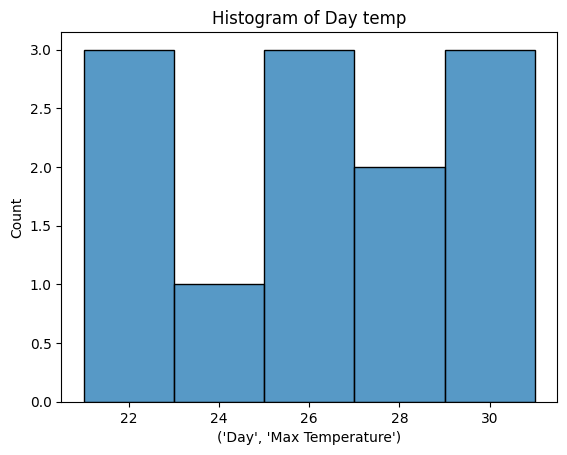

In [65]:
sns.histplot(max_temp,

            ).set_title("Histogram of Day temp")



plt.show()

To count and siplay how many bins does the histogram have, the dollowing code. must be executed

In [66]:
counts, bin_edges = np.histogram(max_temp, bins=10)
counts, bin_edges

(array([1, 2, 0, 1, 2, 1, 0, 2, 2, 1]),
 array([21., 22., 23., 24., 25., 26., 27., 28., 29., 30., 31.]))

To customize the sizes of our bins and bin edges:

Counts: [0 0 1 5 5 1 0 0 0]
Bin edges: [10 14 18 22 26 30 34 38 42 46]


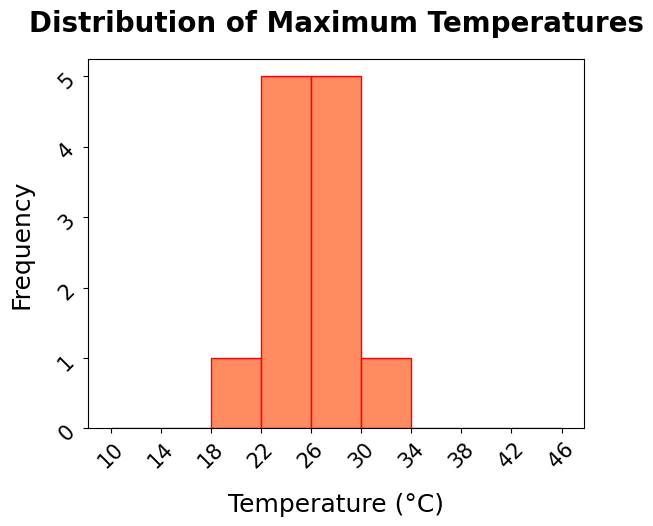

In [67]:
bin_edges = np.arange(10, 50, 4)

# Calculate the histogram counts based on these bin edges if needed
counts, _ = np.histogram(max_temp, bins=bin_edges)
print("Counts:", counts)
print("Bin edges:", bin_edges)

# Plot using sns.histplot with specified bin edges
sns.histplot(max_temp,
             alpha=0.9,
             color='coral',
             edgecolor='red',
             bins=bin_edges)

# Titles and labels
plt.title("Distribution of Maximum Temperatures", fontsize=20, fontweight='bold', pad=20)
plt.xlabel("Temperature (°C)", fontsize=18, labelpad=15)
plt.ylabel("Frequency", fontsize=18, labelpad=15)

# Set xticks and yticks properties
plt.xticks(bin_edges, fontsize=15, rotation=45)
plt.yticks(fontsize=15, rotation=45)

# Display the plot
plt.show()

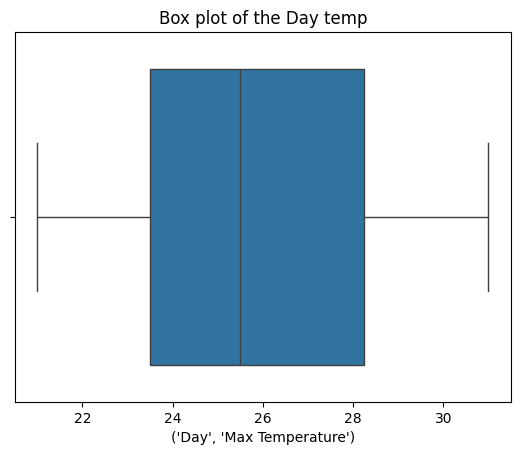

In [70]:
sns.boxplot(
    x = max_temp,
            whis=(0, 100)
           ).set_title("Box plot of the Day temp")

plt.show()

In [73]:
ndf = df.reset_index()
ndf

City      Date              Night                             \
                                   Weather       Wind Max Temperature   
0   Cambridge  01/07/19             Shower  SW 16 mph              17   
1   Cambridge  02/07/19  Scattered showers   E 20 mph              16   
2   Cambridge  03/07/19  Scattered showers  SE 10 mph              16   
3   Cambridge  04/07/19      Mostly cloudy   S 25 mph              16   
4      London  01/07/19             Shower  SW 16 mph              18   
5      London  02/07/19         Heavy rain  SW 16 mph              17   
6      London  03/07/19         Heavy rain  SW 16 mph              19   
7      London  04/07/19      Mostly cloudy  SW 16 mph              23   
8      Oxford  01/07/19             Shower  SW 16 mph              19   
9      Oxford  02/07/19             Shower  SW 16 mph              19   
10     Oxford  03/07/19  Scattered showers  SW 16 mph              22   
11     Oxford  04/07/19             Shower  SW 16 mph              21   

                  Day                             
              Weather       Wind Max Temperature  
0              Shower  SW 16 mph              24  
1   Scattered showers   E 20 mph              21  
2   Scattered showers  SE 10 mph              22  
3              Shower   S 25 mph              22  
4              Shower  SW 16 mph              28  
5              Shower  SW 16 mph              29  
6   Scattered showers  SW 16 mph              29  
7       Mostly cloudy  SW 16 mph              31  
8              Shower  SW 13 mph              25  
9              Shower  SW 16 mph              26  
10  Scattered showers  SW 16 mph              28  
11             Shower  SW 14 mph              25

In [72]:
ndf = df.reset_index()
ndf.columns

MultiIndex([( 'City',                ''),
            ( 'Date',                ''),
            ('Night',         'Weather'),
            ('Night',            'Wind'),
            ('Night', 'Max Temperature'),
            (  'Day',         'Weather'),
            (  'Day',            'Wind'),
            (  'Day', 'Max Temperature')],
           )

#### Plotting the day temperature per city

In [76]:
day_temp = ndf[(  'Day', 'Max Temperature')]
day_temp

,Day
,Max Temperature
0,24
1,21
2,22
3,22
4,28
5,29
6,29
7,31
8,25


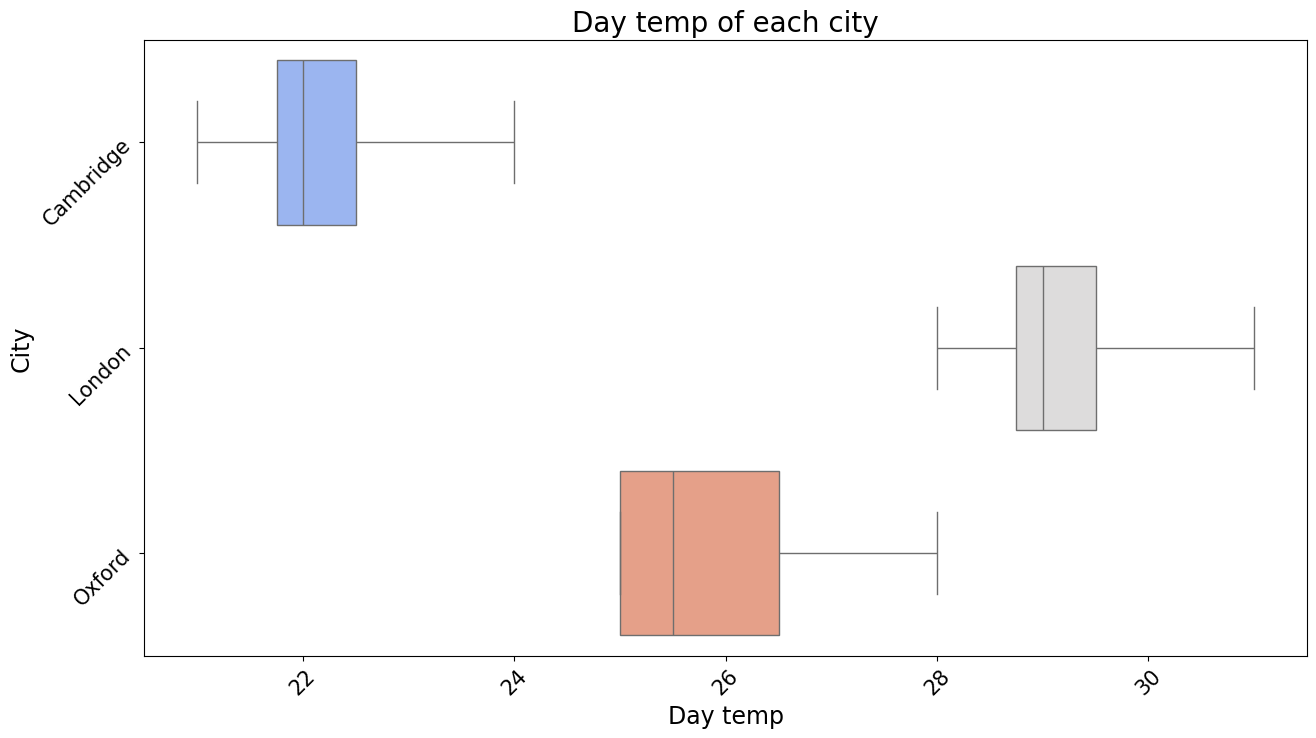

In [77]:
plt.figure(figsize=(15,8))
b = sns.boxplot(x = day_temp,
                y = ndf['City'],
                hue = ndf['City'],
                whis=(0, 100),
                palette="coolwarm",
           )
#plt.xticks(fontsize = 17, rotation = 45)
#plt.yticks(fontsize = 17, rotation = 45)
b.set_xlabel('Day temp', fontsize = 17)
b.set_ylabel('City', fontsize = 17)
b.tick_params(labelsize=15,rotation = 45)
b.axes.set_title("Day temp of each city",fontsize=20)
plt.show()